**Time Deposits (CDs)**

For Time Deposits (e.g., certificates of deposits with fixed maturities), the focus is on variables influencing long-term savings decisions, rate expectations, and risk aversion. Here's the relevance of each:

1. Real GDP: Moderate relevance—economic output levels can signal stability, encouraging long-term commitments to time deposits

2. Real GDP growth: High relevance—growth boosts confidence for locking funds; slowdowns might increase time deposits for security **(*Selected*)**

3. Nominal GDP: Low relevance—includes inflation, which is better captured separately; redundant with real GDP

4. Nominal GDP growth: Low relevance—overlaps with real growth and inflation; less direct for fixed-rate decisions

5. Real disposable income: High relevance—higher income enables allocating funds to time deposits for yield **(*Selected*)**

6. Real disposable income growth: High relevance—rising income growth supports long-term savings in time deposits **(*Selected*)**

7. Nominal disposable income: Low relevance—inflation-distorted; real measures are more accurate for savings capacity

8. Nominal disposable income growth: Low relevance—redundant with real growth and inflation rate

9. Unemployment rate: High relevance—high unemployment reduces long-term savings and increases liquidity needs, negatively impacting time deposits **(*Selected*)**

10. Consumer Price Index (Level): Moderate relevance—absolute price levels affect real yields on fixed rates over time

11. CPI inflation rate: High relevance—inflation erodes fixed returns, influencing decisions to lock in rates before they rise **(*Selected*)**

12. 3-month Treasury rate: Moderate relevance—short-term benchmark; influences rollover decisions for short-maturity CDs

13. 5-year Treasury yield: High relevance—medium-term yield directly competes with 1–5 year time deposit rates **(*Selected*)**

14. 10-year Treasury yield: High relevance—long-term benchmark for longer CDs; depositors compare yields **(*Selected*)**

15. BBB corporate yield: High relevance—risk premium on corporate bonds; higher yields draw funds from time deposits **(*Selected*)**

16. Mortgage rate: Moderate relevance—high rates might divert funds to deposits instead of home financing

17. Prime rate: Moderate relevance—affects bank lending and deposit pricing for term products

18. Dow Jones Total Stock Market Index (Level): Moderate relevance—stock wealth effects can shift funds to/from time deposits

19. House Price Index (Level): Moderate relevance—housing wealth influences long-term savings allocation

20. Commercial Real Estate Price Index (Level): Low relevance—more business-oriented; indirect for retail time deposits

21. Market Volatility Index (Level): High relevance—volatility drives risk aversion, favoring fixed-return time deposits **(*Selected*)**

Variables with moderate relavance have indirect or secondary effects. Including them could add noise without strong predictive power until validated.

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os
os.makedirs('graphs', exist_ok=True)

In [4]:
# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

In [5]:
#Load merged historic data
merged_historic = pd.read_csv('extracted_data/merged_historic.csv', index_col='Date', parse_dates=True)

In [6]:
merged_historic.head()

,Non_Maturity_IB,Non_Interest_Bearing,Time_Deposits,Real GDP,Real GDP growth,Nominal GDP,Nominal GDP growth,Real disposable income,Real disposable income growth,Nominal disposable income,...,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Commercial Real Estate Price Index (Level),Market Volatility Index (Level),Consumer Price Index (Level),Non_IB_Growth,Non_Mat_IB_Growth,Time_Growth,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,,,,,,,
1991-06-30,1098276.374,454615.450,1706710.057,10029.510,3.2,6126.862,6.2,7271.400000,3.0,4474.433333,...,3545.5,75.5,104.6,20.1,135.567,NaN,NaN,NaN,0,0
1991-09-30,1125986.253,475201.761,1679959.999,10080.195,2.0,6205.937,5.3,7299.333333,1.5,4522.066667,...,3744.0,75.2,101.0,21.2,136.600,4.528291,2.523033,-1.567346,0,0
1991-12-31,1184866.053,491843.215,1613051.671,10115.329,1.4,6264.540,3.8,7356.666667,3.2,4590.566667,...,4041.1,75.0,97.6,21.9,137.733,3.501977,5.229176,-3.982733,0,0
1992-03-31,1246734.189,483989.015,1534806.930,10236.435,4.9,6363.102,6.4,7498.600000,7.9,4708.400000,...,3961.6,75.2,95.4,19.8,138.667,-1.596891,5.221530,-4.850728,0,0
1992-06-30,1265699.776,496919.561,1467776.199,10347.429,4.4,6470.763,6.9,7568.933333,3.8,4784.100000,...,3930.3,75.0,93.2,20.2,139.733,2.671661,1.521221,-4.367372,0,0


In [7]:
# Time deposits (endogenous variable)
y = merged_historic['Time_Deposits']

In [8]:
print("Time deposits Statistics")
y.describe() 

Time deposits Statistics


count    1.310000e+02
mean     1.781209e+06
std      3.905313e+05
min      1.205898e+06
25%      1.555535e+06
50%      1.673622e+06
75%      1.934110e+06
max      2.870392e+06
Name: Time_Deposits, dtype: float64

In [9]:
from statsmodels.tsa.stattools import adfuller

In [10]:
# ADF test on original series
adf_result_diff = adfuller(y)
print(f'ADF Statistic (diff=1): {adf_result_diff[0]:.4f}')
print(f'p-value (diff=1): {adf_result_diff[1]:.4f}')
print(f'Critical Values (diff=1): {adf_result_diff[4]}')
if adf_result_diff[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary')

ADF Statistic (diff=1): -3.0618
p-value (diff=1): 0.0295
Critical Values (diff=1): {'1%': -3.4825006939887997, '5%': -2.884397984161377, '10%': -2.578960197753906}
Stationary


Can reject null hypothesis, from the above stats. Original series itself is stationary.

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

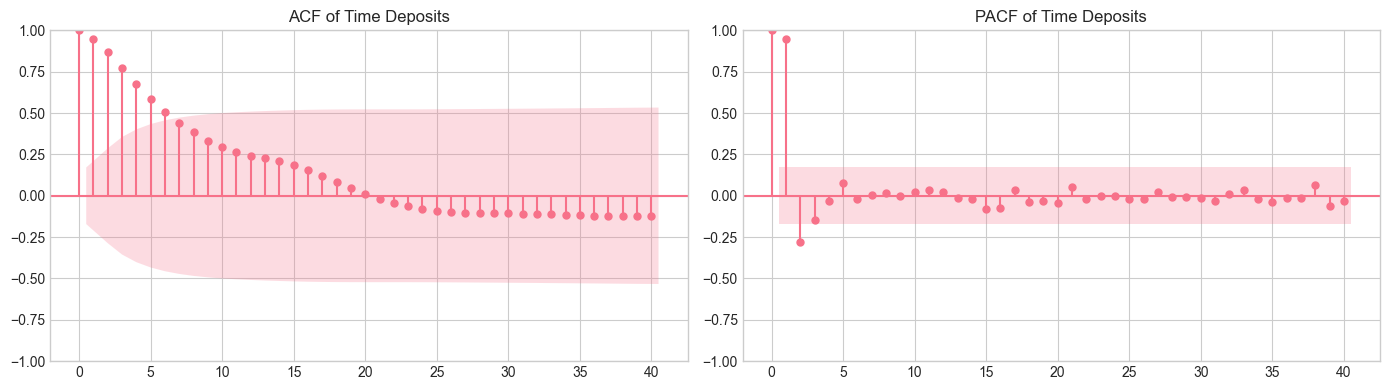

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=40, ax=axes[0])
axes[0].set_title('ACF of Time Deposits')
plot_pacf(y, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of Time Deposits')
plt.tight_layout()
# plt.savefig('graphs/time_dep/time_deposits_acf_pacf.png')
plt.show()

In [13]:
# First Difference
y_diff = y.diff().dropna()

In [14]:
# ADF test on First Difference series
adf_result_diff = adfuller(y_diff)
print(f'ADF Statistic (diff=1): {adf_result_diff[0]:.4f}')
print(f'p-value (diff=1): {adf_result_diff[1]:.4f}')
print(f'Critical Values (diff=1): {adf_result_diff[4]}')
if adf_result_diff[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=1 (d=1 likely needed)')

ADF Statistic (diff=1): -3.8959
p-value (diff=1): 0.0021
Critical Values (diff=1): {'1%': -3.4837793736959997, '5%': -2.88495387648, '10%': -2.579256976}
Stationary after diff=1 (d=1 likely needed)


In [15]:
from statsmodels.tsa.stattools import kpss

In [16]:
# KPSS test with proper interpretation
kpss_stat, p_value, lags, critical_values = kpss(y_diff.dropna(), regression='c')

print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"P-value: {p_value:.4f} (lower bound)")
print(f"Lags used: {lags}")
print(f"Critical Values: {critical_values}")

# Better interpretation accounting for the warning
if kpss_stat < critical_values['10%']:
    print(f"KPSS: Strong evidence of stationarity (stat {kpss_stat:.4f} < 10% critical {critical_values['10%']:.3f})")
    print("Note: Actual p-value > 0.10, indicating very strong stationarity")
elif p_value > 0.05:
    print("KPSS: Series is stationary")
else:
    print("KPSS: Series is non-stationary")


KPSS Statistic: 0.1217
P-value: 0.1000 (lower bound)
Lags used: 6
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
KPSS: Strong evidence of stationarity (stat 0.1217 < 10% critical 0.347)
Note: Actual p-value > 0.10, indicating very strong stationarity


/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_56062/3607429990.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_value, lags, critical_values = kpss(y_diff.dropna(), regression='c')


In [17]:
from arch.unitroot import PhillipsPerron

In [18]:
# Phillips–Perron test on first differenced data
pp_test = PhillipsPerron(y_diff.dropna(), lags=None, trend='c')
print(pp_test.summary())

# Access individual results
print(f"PP Statistic: {pp_test.stat:.4f}")
print(f"P-value: {pp_test.pvalue:.10f}")
print(f"Lags: {pp_test.lags}")
print(f"Critical Values: {pp_test.critical_values}")


     Phillips-Perron Test (Z-tau)    
Test Statistic                 -3.241
P-value                         0.018
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.48 (1%), -2.88 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.
PP Statistic: -3.2411
P-value: 0.0177258120
Lags: 13
Critical Values: {'1%': -3.482087964046026, '5%': -2.8842185101614626, '10%': -2.578864381347275}


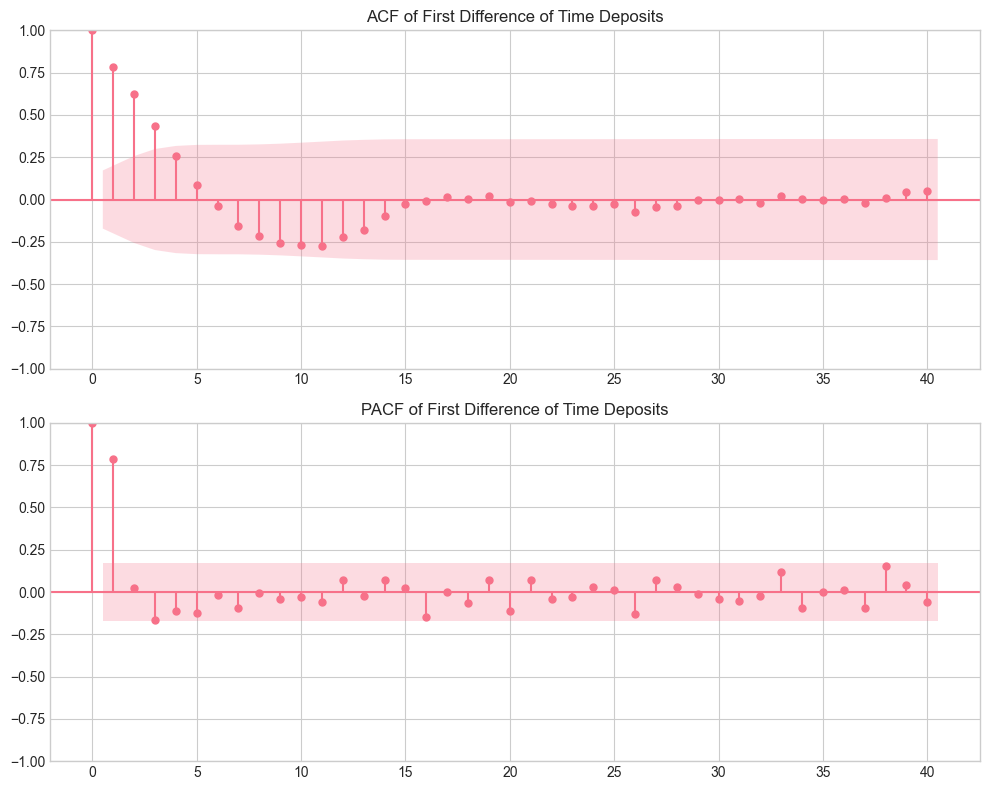

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plot_acf(y_diff, lags=40, ax=axes[0])
axes[0].set_title('ACF of First Difference of Time Deposits')
plot_pacf(y_diff, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of First Difference of Time Deposits')
plt.tight_layout()
plt.savefig('graphs/time_dep/time_deposits_acf_pacf.png')
plt.show()

In [20]:
# Selected exogenous variables
# exogs = ['Real GDP growth', 'Real disposable income', 'Real disposable income growth', 'Unemployment rate', 'CPI inflation rate', '5-year Treasury yield', '10-year Treasury yield','BBB corporate yield', 'Market Volatility Index (Level)','GFC_Dummy', 'COVID_Dummy']
exogs = ['Real GDP','Real GDP growth', 'Real disposable income', 'Real disposable income growth', 'Unemployment rate','Consumer Price Index (Level)', 'CPI inflation rate', '3-month Treasury rate', '5-year Treasury yield', '10-year Treasury yield','BBB corporate yield', 'Mortgage rate', 'Prime rate', 'Dow Jones Total Stock Market Index (Level)', 'House Price Index (Level)', 'Market Volatility Index (Level)','GFC_Dummy', 'COVID_Dummy']
X = merged_historic[exogs]

In [21]:
print("Statistics of Economic Variables relevant to Time deposits")
X.describe() 

Statistics of Economic Variables relevant to Time deposits


,Real GDP,Real GDP growth,Real disposable income,Real disposable income growth,Unemployment rate,Consumer Price Index (Level),CPI inflation rate,3-month Treasury rate,5-year Treasury yield,10-year Treasury yield,BBB corporate yield,Mortgage rate,Prime rate,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level),GFC_Dummy,COVID_Dummy
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,16150.481405,2.633588,11918.363613,2.884733,5.756489,206.690191,2.580153,2.432061,3.600000,4.213740,5.875573,5.825954,5.647328,16558.692366,152.122137,26.822137,0.061069,0.061069
std,3480.557340,4.561943,2860.052782,7.658806,1.773441,44.647620,2.208251,2.073172,2.021804,1.896343,1.816509,1.741246,2.122420,11278.105271,61.373739,11.684528,0.240376,0.240376
min,10029.510000,-28.000000,7271.400000,-27.600000,3.500000,135.567000,-8.900000,0.000000,0.300000,0.600000,2.300000,2.800000,3.300000,3545.500000,74.900000,12.700000,0.000000,0.000000
25%,13515.759500,1.550000,9508.066667,1.350000,4.400000,166.583500,1.750000,0.200000,1.700000,2.500000,4.400000,4.200000,3.300000,9342.600000,96.750000,19.450000,0.000000,0.000000
50%,16485.350000,2.600000,12075.633333,2.800000,5.400000,207.939000,2.700000,2.000000,3.400000,4.200000,5.800000,5.900000,5.200000,12808.900000,143.200000,23.500000,0.000000,0.000000
75%,18874.812000,4.050000,13977.366667,4.300000,6.750000,237.763000,3.500000,4.650000,5.350000,5.800000,7.200000,7.150000,8.000000,21523.050000,188.500000,31.950000,0.000000,0.000000
max,22679.255000,34.800000,18378.266667,56.000000,13.000000,308.099000,9.700000,6.000000,7.800000,8.300000,10.100000,9.500000,9.500000,48634.300000,310.500000,82.700000,1.000000,1.000000


In [22]:
# Exclude the last two columns from X
X_no_dummies = X.iloc[:, :-2]
X_no_dummies.head()

,Real GDP,Real GDP growth,Real disposable income,Real disposable income growth,Unemployment rate,Consumer Price Index (Level),CPI inflation rate,3-month Treasury rate,5-year Treasury yield,10-year Treasury yield,BBB corporate yield,Mortgage rate,Prime rate,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level)
Date,,,,,,,,,,,,,,,,
1991-06-30,10029.510,3.2,7271.400000,3.0,6.8,135.567,2.4,5.6,7.8,8.3,10.1,9.5,8.7,3545.5,75.5,20.1
1991-09-30,10080.195,2.0,7299.333333,1.5,6.9,136.600,3.1,5.4,7.5,8.1,9.8,9.3,8.4,3744.0,75.2,21.2
1991-12-31,10115.329,1.4,7356.666667,3.2,7.1,137.733,3.4,4.5,6.7,7.5,9.2,8.7,7.6,4041.1,75.0,21.9
1992-03-31,10236.435,4.9,7498.600000,7.9,7.4,138.667,2.7,3.9,6.7,7.5,8.9,8.7,6.5,3961.6,75.2,19.8
1992-06-30,10347.429,4.4,7568.933333,3.8,7.6,139.733,3.1,3.7,6.7,7.5,8.6,8.7,6.5,3930.3,75.0,20.2


In [23]:
# Differencing the Economic Varibles with "Levels"/ Absolute data

X_levels = pd.DataFrame(index=X.index)
with_levels = ['Real GDP', 'Real disposable income', 'Consumer Price Index (Level)', 'Dow Jones Total Stock Market Index (Level)', 
               'House Price Index (Level)', 'Market Volatility Index (Level)']

for var in with_levels:
    X_levels[var] = X[var]


In [24]:
X_levels

,Real GDP,Real disposable income,Consumer Price Index (Level),Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level)
Date,,,,,,
1991-06-30,10029.510,7271.400000,135.567,3545.5,75.5,20.1
1991-09-30,10080.195,7299.333333,136.600,3744.0,75.2,21.2
1991-12-31,10115.329,7356.666667,137.733,4041.1,75.0,21.9
1992-03-31,10236.435,7498.600000,138.667,3961.6,75.2,19.8
1992-06-30,10347.429,7568.933333,139.733,3930.3,75.0,20.2
...,...,...,...,...,...,...
2022-12-31,21989.981,16239.400000,298.441,38520.6,295.9,33.6
2023-03-31,22112.329,16662.733333,301.203,41136.6,299.4,26.5
2023-06-30,22225.350,16797.300000,303.467,44411.5,303.0,20.1


In [25]:
# Function to run tests and get results
def run_stationarity_tests(series):
    results = {}
    # Original series
    adf = adfuller(series.dropna(), regression='c')
    kpss_result = kpss(series.dropna(), regression='c')
    pp = PhillipsPerron(series.dropna(), trend='c', lags=None)  # Using arch.unitroot PhillipsPerron
    results['orig'] = {
        'adf_stat': adf[0], 'adf_p': adf[1], 'adf_5%': adf[4]['5%'],
        'kpss_stat': kpss_result[0], 'kpss_p': kpss_result[1], 'kpss_5%': kpss_result[3]['5%'],
        'pp_stat': pp.stat, 'pp_p': pp.pvalue, 'pp_5%': pp.critical_values['5%']
    }
    # First difference
    diff1 = series.diff().dropna()
    adf_diff1 = adfuller(diff1, regression='c')
    kpss_diff1 = kpss(diff1, regression='c')
    pp_diff1 = PhillipsPerron(diff1, trend='c', lags=None)
    results['diff1'] = {
        'adf_stat': adf_diff1[0], 'adf_p': adf_diff1[1], 'adf_5%': adf_diff1[4]['5%'],
        'kpss_stat': kpss_diff1[0], 'kpss_p': kpss_diff1[1], 'kpss_5%': kpss_diff1[3]['5%'],
        'pp_stat': pp_diff1.stat, 'pp_p': pp_diff1.pvalue, 'pp_5%': pp_diff1.critical_values['5%']
    }
    # Second difference
    diff2 = diff1.diff().dropna()
    adf_diff2 = adfuller(diff2, regression='c')
    kpss_diff2 = kpss(diff2, regression='c')
    pp_diff2 = PhillipsPerron(diff2, trend='c', lags=None)
    results['diff2'] = {
        'adf_stat': adf_diff2[0], 'adf_p': adf_diff2[1], 'adf_5%': adf_diff2[4]['5%'],
        'kpss_stat': kpss_diff2[0], 'kpss_p': kpss_diff2[1], 'kpss_5%': kpss_diff2[3]['5%'],
        'pp_stat': pp_diff2.stat, 'pp_p': pp_diff2.pvalue, 'pp_5%': pp_diff2.critical_values['5%']
    }
    return results

In [26]:
# Differencing the Economic Varibles with "Levels"/ Absolute data
# Run tests for each exogenous variable
for var in with_levels:
    results = run_stationarity_tests(X_levels[var])
    print(f"\n{var}:")
    for diff, stats in results.items():
        print(f"{diff}:")
        print(f"  ADF Statistic: {stats['adf_stat']:.4f}, p-value: {stats['adf_p']:.4f}, 5% CI: {stats['adf_5%']:.4f}")
        print(f"  KPSS Statistic: {stats['kpss_stat']:.4f}, p-value: {stats['kpss_p']:.4f}, 5% CI: {stats['kpss_5%']:.4f}")
        print(f"  PP Statistic: {stats['pp_stat']:.4f}, p-value: {stats['pp_p']:.4f}, 5% CI: {stats['pp_5%']:.4f}")


Real GDP:
orig:
  ADF Statistic: 0.0285, p-value: 0.9608, 5% CI: -2.8842
  KPSS Statistic: 1.9384, p-value: 0.0100, 5% CI: 0.4630
  PP Statistic: 0.2210, p-value: 0.9734, 5% CI: -2.8840
diff1:
  ADF Statistic: -13.7418, p-value: 0.0000, 5% CI: -2.8842
  KPSS Statistic: 0.0843, p-value: 0.1000, 5% CI: 0.4630
  PP Statistic: -14.7700, p-value: 0.0000, 5% CI: -2.8842
diff2:
  ADF Statistic: -7.3715, p-value: 0.0000, 5% CI: -2.8857
  KPSS Statistic: 0.2235, p-value: 0.1000, 5% CI: 0.4630
  PP Statistic: -53.8563, p-value: 0.0000, 5% CI: -2.8844

Real disposable income:
orig:
  ADF Statistic: -0.1096, p-value: 0.9485, 5% CI: -2.8853
  KPSS Statistic: 1.9286, p-value: 0.0100, 5% CI: 0.4630
  PP Statistic: -0.0071, p-value: 0.9579, 5% CI: -2.8840
diff1:
  ADF Statistic: -6.5812, p-value: 0.0000, 5% CI: -2.8853
  KPSS Statistic: 0.1270, p-value: 0.1000, 5% CI: 0.4630
  PP Statistic: -19.9187, p-value: 0.0000, 5% CI: -2.8842
diff2:
  ADF Statistic: -6.9690, p-value: 0.0000, 5% CI: -2.8862
  KP

/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_56062/3820424706.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series.dropna(), regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_56062/3820424706.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff1 = kpss(diff1, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_56062/3820424706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff2 = kpss(diff2, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_56062/3820424706.py:6: InterpolationWarning: The tes

In [27]:
X_updated = pd.DataFrame(index=X.index)

# Columns to exclude and difference
exclude_cols = [
    'Real GDP',
    'Real disposable income',
    'Consumer Price Index (Level)', 
    'Dow Jones Total Stock Market Index (Level)', 
    'House Price Index (Level)'
]

# Drop excluded columns
X_updated = X.drop(columns=exclude_cols).copy()

# Add differenced versions of excluded columns
for col in exclude_cols:
    X_updated[f"{col}_diff"] = X[col].diff()

In [28]:
X_updated

,Real GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,5-year Treasury yield,10-year Treasury yield,BBB corporate yield,Mortgage rate,Prime rate,Market Volatility Index (Level),GFC_Dummy,COVID_Dummy,Real GDP_diff,Real disposable income_diff,Consumer Price Index (Level)_diff,Dow Jones Total Stock Market Index (Level)_diff,House Price Index (Level)_diff
Date,,,,,,,,,,,,,,,,,,
1991-06-30,3.2,3.0,6.8,2.4,5.6,7.8,8.3,10.1,9.5,8.7,20.1,0,0,NaN,NaN,NaN,NaN,NaN
1991-09-30,2.0,1.5,6.9,3.1,5.4,7.5,8.1,9.8,9.3,8.4,21.2,0,0,50.685,27.933333,1.033,198.5,-0.3
1991-12-31,1.4,3.2,7.1,3.4,4.5,6.7,7.5,9.2,8.7,7.6,21.9,0,0,35.134,57.333333,1.133,297.1,-0.2
1992-03-31,4.9,7.9,7.4,2.7,3.9,6.7,7.5,8.9,8.7,6.5,19.8,0,0,121.106,141.933333,0.934,-79.5,0.2
1992-06-30,4.4,3.8,7.6,3.1,3.7,6.7,7.5,8.6,8.7,6.5,20.2,0,0,110.994,70.333333,1.066,-31.3,-0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31,2.6,2.2,3.6,4.2,4.0,4.1,3.9,6.1,6.7,6.8,33.6,0,0,138.847,87.533333,2.932,2422.6,0.1
2023-03-31,2.2,10.8,3.5,3.8,4.6,3.8,3.7,5.6,6.4,7.7,26.5,0,0,122.348,423.333333,2.762,2616.0,3.5
2023-06-30,2.1,3.3,3.6,2.7,5.1,3.7,3.7,5.7,6.5,8.2,20.1,0,0,113.021,134.566667,2.264,3274.9,3.6


In [29]:
from statsmodels.tsa.stattools import grangercausalitytests

In [30]:
granger_results = {}

for col in X_updated.columns:
    if 'Dummy' in col:
        continue
    data = pd.concat([y_diff, X_updated[col]], axis=1).dropna()
    data.columns = ['deposits', col]
    
    print(f"\nGranger Causality Test between Time Deposits and {col}")
    # Call without the deprecated verbose argument
    test_result = grangercausalitytests(data, maxlag=4)
    
    p_values = {
        f'lag_{lag}': round(test_result[lag][0]['ssr_ftest'][1], 4)
        for lag in range(1, 5)
    }
    granger_results[col] = p_values

granger_df = pd.DataFrame(granger_results).T
print("\nGranger Causality Test Results (p-values):")
print(granger_df)

print("\nSignificant Granger causality (p < 0.05):")
for var, row in granger_df.iterrows():
    for lag, p in row.items():
        if p < 0.05:
            print(f"{var} at {lag}: p = {p}")



Granger Causality Test between Time Deposits and Real GDP growth

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=6.8712  , p=0.0098  , df_denom=126, df_num=1
ssr based chi2 test:   chi2=7.0348  , p=0.0080  , df=1
likelihood ratio test: chi2=6.8497  , p=0.0089  , df=1
parameter F test:         F=6.8712  , p=0.0098  , df_denom=126, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=5.0514  , p=0.0078  , df_denom=123, df_num=2
ssr based chi2 test:   chi2=10.5135 , p=0.0052  , df=2
likelihood ratio test: chi2=10.1040 , p=0.0064  , df=2
parameter F test:         F=5.0514  , p=0.0078  , df_denom=123, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3.6204  , p=0.0152  , df_denom=120, df_num=3
ssr based chi2 test:   chi2=11.4947 , p=0.0093  , df=3
likelihood ratio test: chi2=11.0039 , p=0.0117  , df=3
parameter F test:         F=3.6204  , p=0.0152  , df_denom=120, df_num=3

Granger Causality
number of

Key drivers of deposits (with lags): Real GDP growth, Real disposable income growth, Unemployment, 5-year Treasury yield, House prices, CPI inflation, 3-month Treasury rate, CPI level_diff

No evidence of causality: Prime rate, VIX, Stock market returns

Deposits are not random — they reflect fundamental macro conditions. Households increase NMDs when income grows, yields fall, or uncertainty about jobs/economy rises. They decline when inflation or housing costs eat into liquidity, or when bond yields offer better alternatives

In [31]:
# Original dataframe X and deposits series
# X: contains columns ['Real GDP','Real GDP growth', 'Real disposable income', 'Real disposable income growth', 
#                       'Unemployment rate','Consumer Price Index (Level)', 'CPI inflation rate', '3-month Treasury rate', 
#                       '5-year Treasury yield', '10-year Treasury yield','BBB corporate yield', 'Mortgage rate', 'Prime rate', 
#                       'Dow Jones Total Stock Market Index (Level)', 'House Price Index (Level)', 'Market Volatility Index (Level)',
#                       'GFC_Dummy', 'COVID_Dummy']
# y: time deposits series

#Create lagged variables
exog_lags = pd.DataFrame({
    'Real GDP_lag2': X_updated['Real GDP_diff'].shift(2),
    'Real GDP growth_lag2': X_updated['Real GDP growth'].shift(2),
    # 'Real disposable income_diff_lag4': X_updated['Real disposable income_diff'].shift(4),
    # 'Real disposable income growth_lag1': X_updated['Real disposable income growth'].shift(1),
    'Unemployment rate_lag1': X_updated['Unemployment rate'].shift(1),
    'CPI Price Index (Level)_diff_lag1': X_updated['Consumer Price Index (Level)_diff'].shift(1),
    'CPI inflation rate_lag2': X_updated['CPI inflation rate'].shift(2),
    '3-month Treasury rate_lag2': X_updated['3-month Treasury rate'].shift(2),
    '5-year Treasury yield_lag2': X_updated['5-year Treasury yield'].shift(2),
    '10-year Treasury yield_lag2': X_updated['10-year Treasury yield'].shift(2),
    'BBB corporate yield_lag2': X_updated['BBB corporate yield'].shift(2),
    'Mortgage rate_lag2': X_updated['Mortgage rate'].shift(2),
    'Prime rate_lag2': X_updated['Prime rate'].shift(2),
    # 'Dow Jones Total Stock Market Index (Level)_diff_lag1': X_updated['Dow Jones Total Stock Market Index (Level)_diff'].shift(1),
    'House Price Index (Level)_diff_lag3': X_updated['House Price Index (Level)_diff'].shift(3),
    'Market Volatility Index (Level)_lag1': X_updated['Market Volatility Index (Level)'].shift(1),
    'GFC_Dummy': X_updated['GFC_Dummy'],
    'COVID_Dummy': X_updated['COVID_Dummy']
})

# Drop rows with NaNs from lagging
exog_final = exog_lags.dropna()

In [32]:
exog_final.head()

,Real GDP_lag2,Real GDP growth_lag2,Unemployment rate_lag1,CPI Price Index (Level)_diff_lag1,CPI inflation rate_lag2,3-month Treasury rate_lag2,5-year Treasury yield_lag2,10-year Treasury yield_lag2,BBB corporate yield_lag2,Mortgage rate_lag2,Prime rate_lag2,House Price Index (Level)_diff_lag3,Market Volatility Index (Level)_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,
1992-06-30,35.134,1.4,7.4,0.934,3.4,4.5,6.7,7.5,9.2,8.7,7.6,-0.3,19.8,0,0
1992-09-30,121.106,4.9,7.6,1.066,2.7,3.9,6.7,7.5,8.9,8.7,6.5,-0.2,20.2,0,0
1992-12-31,110.994,4.4,7.6,1.067,3.1,3.7,6.7,7.5,8.6,8.7,6.5,0.2,16.2,0,0
1993-03-31,102.244,4.0,7.4,1.233,3.1,3.1,5.7,6.9,7.9,8.0,6.0,-0.2,21.0,0,0
1993-06-30,108.975,4.2,7.1,1.034,3.6,3.1,6.0,7.0,8.1,8.2,6.0,-0.1,16.2,0,0


In [33]:
exog_final.tail(15)

,Real GDP_lag2,Real GDP growth_lag2,Unemployment rate_lag1,CPI Price Index (Level)_diff_lag1,CPI inflation rate_lag2,3-month Treasury rate_lag2,5-year Treasury yield_lag2,10-year Treasury yield_lag2,BBB corporate yield_lag2,Mortgage rate_lag2,Prime rate_lag2,House Price Index (Level)_diff_lag3,Market Volatility Index (Level)_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,
2020-06-30,133.507,2.6,3.8,0.879,2.8,1.6,1.6,1.8,3.3,3.7,4.8,2.5,82.7,0,1
2020-09-30,-285.535,-5.3,13.0,-2.441,1.4,1.1,1.2,1.4,3.4,3.5,4.4,3.1,57.1,0,1
2020-12-31,-1630.723,-28.0,8.8,2.916,-3.8,0.1,0.4,0.7,3.4,3.2,3.3,3.1,33.6,0,1
2021-03-31,1476.955,34.8,6.7,1.808,4.6,0.1,0.3,0.6,2.4,3.0,3.3,1.6,40.3,0,1
2021-06-30,212.343,4.2,6.2,2.620,2.8,0.1,0.4,0.9,2.3,2.8,3.3,7.3,37.2,0,1
2021-09-30,266.413,5.2,5.9,4.953,4.2,0.1,0.6,1.4,2.4,2.9,3.3,8.5,27.6,0,1
2021-12-31,319.003,6.2,5.1,4.267,7.5,0.0,0.8,1.6,2.6,3.0,3.3,7.5,25.7,0,1
2022-03-31,173.539,3.3,4.2,5.790,6.6,0.0,0.8,1.4,2.4,2.9,3.3,11.7,31.1,0,0
2022-06-30,364.519,7.0,3.8,6.146,8.8,0.1,1.2,1.6,2.7,3.1,3.3,11.1,36.5,0,0


In [35]:
# Ensure y and exog_final share the same DateTimeIndex

# Join on index to drop mismatches
data = pd.concat([y, exog_final], axis=1).dropna()
y_aligned = data[y.name]
exog_aligned = data[exog_final.columns]

In [36]:
y_aligned.head()

Date
1992-06-30    1467776.199
1992-09-30    1404153.533
1992-12-31    1337713.371
1993-03-31    1287128.030
1993-06-30    1260218.077
Freq: QE-DEC, Name: Time_Deposits, dtype: float64

In [53]:
import math

In [54]:
import dcor
from scipy.stats import pearsonr

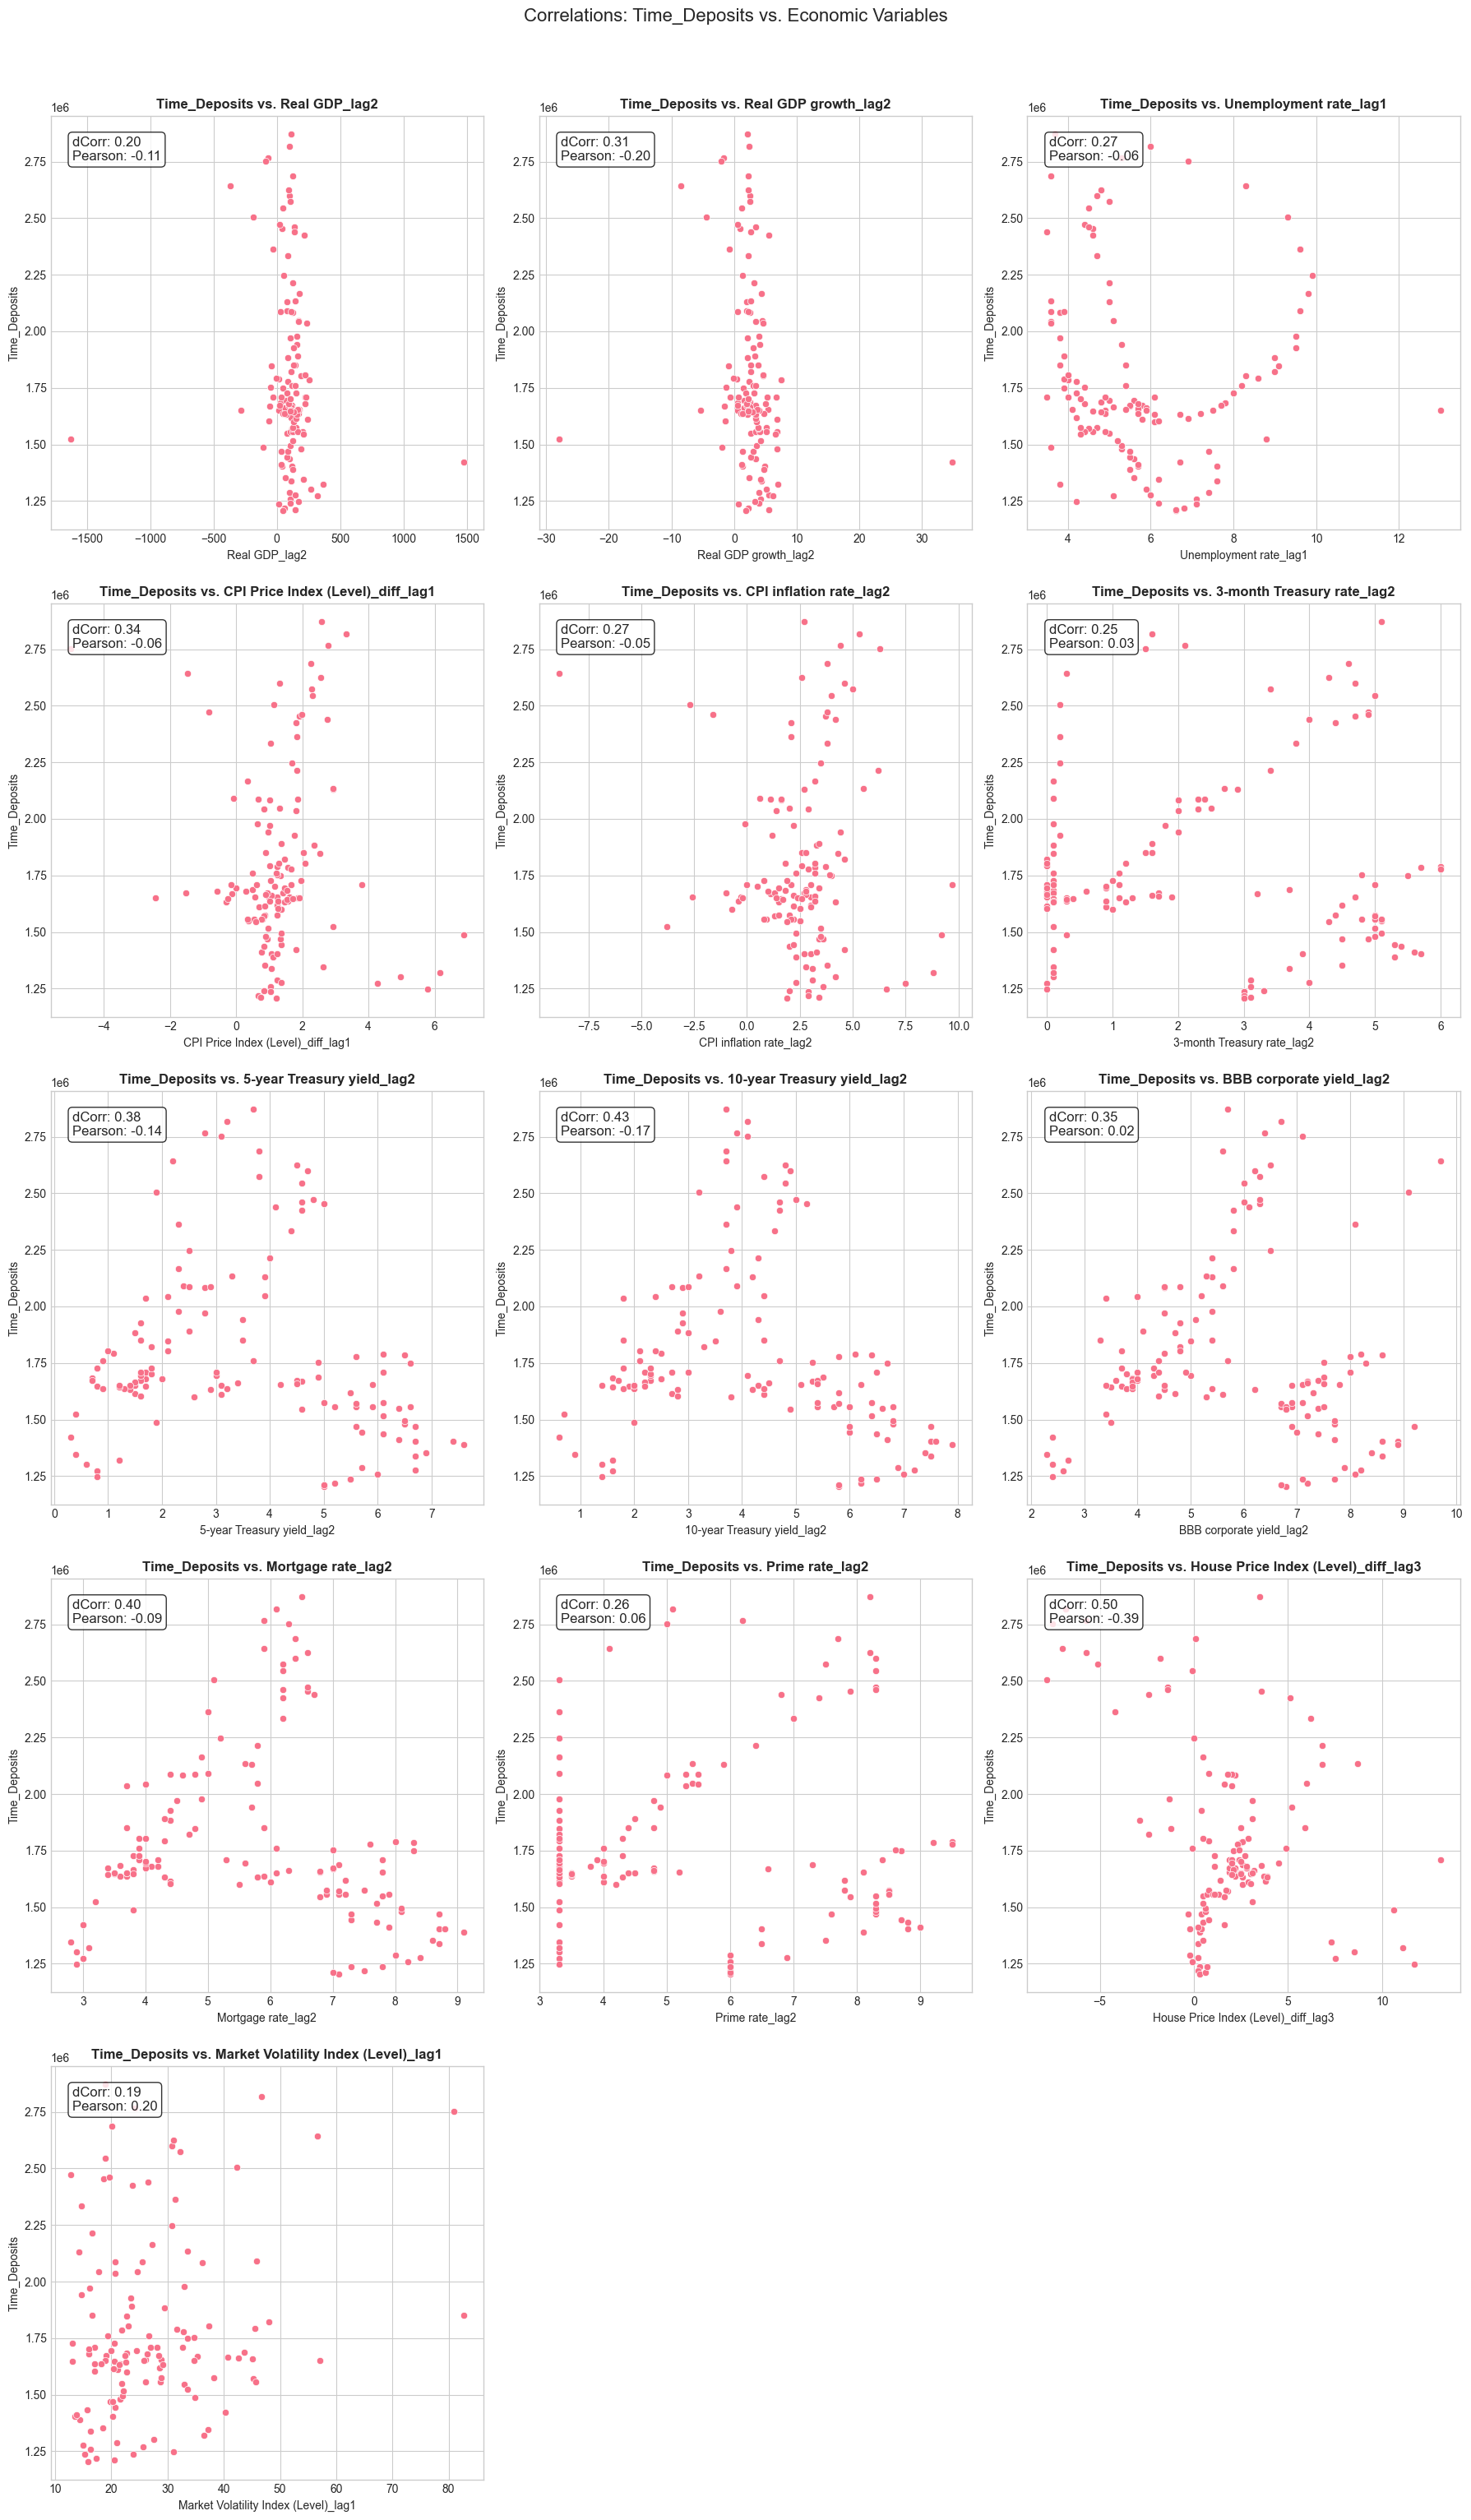

Economic variables ranked by Distance Correlation:
                   Economic Variable dCorr
 House Price Index (Level)_diff_lag3  0.50
         10-year Treasury yield_lag2  0.43
                  Mortgage rate_lag2  0.40
          5-year Treasury yield_lag2  0.38
            BBB corporate yield_lag2  0.35
   CPI Price Index (Level)_diff_lag1  0.34
                Real GDP growth_lag2  0.31
             CPI inflation rate_lag2  0.27
              Unemployment rate_lag1  0.27
                     Prime rate_lag2  0.26
          3-month Treasury rate_lag2  0.25
                       Real GDP_lag2  0.20
Market Volatility Index (Level)_lag1  0.19

Economic variables ranked by Pearson Correlation:
                   Economic Variable Pearson
Market Volatility Index (Level)_lag1    0.20
                     Prime rate_lag2    0.06
          3-month Treasury rate_lag2    0.03
            BBB corporate yield_lag2    0.02
             CPI inflation rate_lag2   -0.05
   CPI Price Index (Level)

In [56]:
# Correlation Graphs 

deposit_col = y_aligned.name   # Only one deposit column (Series)
econ_cols = exog_aligned.columns[:-2]  # excluding last 2 dummy cols

# Store results
results = []

# Grid size: n rows, 3 columns
n_rows = math.ceil(len(econ_cols) / 3)
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 6 * n_rows))
axes = axes.flatten()  # Flatten to 1D array for easy iteration

for i, econ in enumerate(econ_cols):
    # Compute correlations
    dcorr_value = dcor.distance_correlation(y_aligned, exog_aligned[econ])
    pearson_corr, _ = pearsonr(y_aligned, exog_aligned[econ])
    
    # Save to results
    results.append({
        "Economic Variable": econ,
        "dCorr": dcorr_value,
        "Pearson": pearson_corr
    })
    
    # Scatter plot
    sns.scatterplot(x=exog_aligned[econ], y=y_aligned, ax=axes[i])
    axes[i].text(
        0.05, 0.95,
        f'dCorr: {dcorr_value:.2f}\nPearson: {pearson_corr:.2f}',
        transform=axes[i].transAxes,
        fontsize=12,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )
    axes[i].set_title(f'{deposit_col} vs. {econ}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(econ, fontsize=10)
    axes[i].set_ylabel(deposit_col, fontsize=10)
    axes[i].tick_params(labelsize=10)

# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f'Correlations: {deposit_col} vs. Economic Variables', y=1.02, fontsize=16)
plt.tight_layout()
plt.savefig(f'graphs/time_dep/time_dep_all_corr_plots.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- Create sorted tables ----
results_df = pd.DataFrame(results)

# Sort by distance correlation
dcorr_sorted = results_df.sort_values("dCorr", ascending=False).copy()
dcorr_sorted["dCorr"] = dcorr_sorted["dCorr"].map(lambda x: f"{x:.2f}")
print("Economic variables ranked by Distance Correlation:")
print(dcorr_sorted[["Economic Variable", "dCorr"]].to_string(index=False))

# Sort by Pearson correlation
pearson_sorted = results_df.sort_values("Pearson", ascending=False).copy()
pearson_sorted["Pearson"] = pearson_sorted["Pearson"].map(lambda x: f"{x:.2f}")
print("\nEconomic variables ranked by Pearson Correlation:")
print(pearson_sorted[["Economic Variable", "Pearson"]].to_string(index=False))


In [37]:
import pmdarima as pm

In [38]:
# y_aligned: pandas Series of the target variable with DateTimeIndex
# exog_aligned: pandas DataFrame of exogenous regressors with same index

auto_model = pm.auto_arima(
    y=y_aligned,
    exogenous=exog_aligned,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=4,              # quarterly
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='aic',
    stepwise=True,
    trace=True,
    error_action='ignore'
    # omit n_jobs to avoid the parallel warning
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[4] intercept   : AIC=3217.518, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[4] intercept   : AIC=3266.943, Time=0.03 sec
 ARIMA(0,1,1)(0,0,1)[4] intercept   : AIC=3206.716, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[4]             : AIC=3217.739, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[4] intercept   : AIC=3205.934, Time=0.01 sec
 ARIMA(0,1,1)(1,0,0)[4] intercept   : AIC=3206.884, Time=0.07 sec
 ARIMA(0,1,1)(1,0,1)[4] intercept   : AIC=3208.080, Time=0.10 sec
 ARIMA(1,1,1)(0,0,0)[4] intercept   : AIC=3256.905, Time=0.03 sec
 ARIMA(0,1,2)(0,0,0)[4] intercept   : AIC=3207.777, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[4] intercept   : AIC=3266.986, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[4] intercept   : AIC=3254.717, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[4]             : AIC=3205.124, Time=0.01 sec
 ARIMA(0,1,1)(1,0,0)[4]             : AIC=3205.796, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[4]             : AIC=3205.625, Time=0.02 sec
 ARIMA(0,1,1)(1,0,1)[4]          

#### Time series cross-validation

Anchor rolling windows around the key regime shifts rather than fixed jumps.


1992-06-30 → 1999-12-31 trains up to just before Q1 2000, tests Q1 2000–Q4 2001 (dot-com aftermath).

1994-06-30 → 2001-12-31 shifts forward 2 years, so training now covers the dot-com peak and early GFC build-up; tests Q1 2002–Q4 2003.

1999-06-30 → 2006-12-31 captures the full build-up to the GFC; tests Q1 2007–Q4 2008 (GFC onset).

2004-06-30 → 2011-12-31 trains through the GFC trough and early recovery; tests Q1 2012–Q4 2013.

2009-06-30 → 2016-12-31 starts mid-crisis recovery through the pre-COVID expansion; tests Q1 2017–Q4 2018.

2014-06-30 → 2021-06-30 trains through the COVID shock and stimulus period; tests Q3 2021–Q4 2023.

In [34]:
import statsmodels.api as sm

In [39]:
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error

In [40]:
import matplotlib.dates as mdates

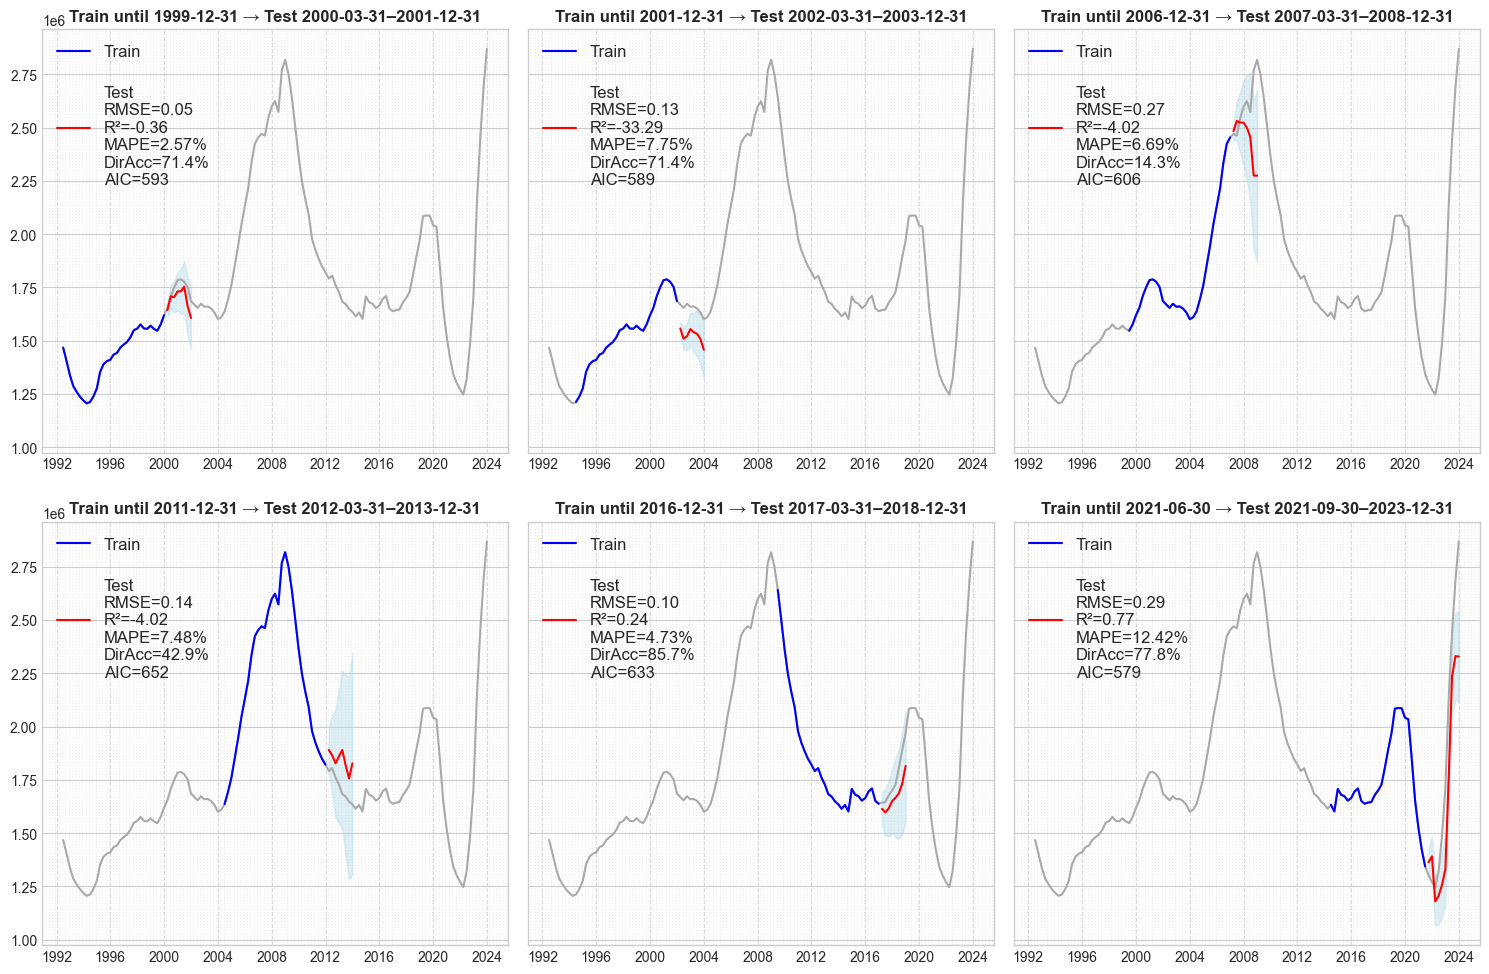

In [41]:
# Cross-validation folds
folds = [
    # Pre-dot-com test
    ('1992-06-30', '1999-12-31', '2000-03-31', '2001-12-31'),
    # Dot-com + early GFC test
    ('1994-06-30', '2001-12-31', '2002-03-31', '2003-12-31'),
    # Run-up through the GFC test
    ('1999-06-30', '2006-12-31', '2007-03-31', '2008-12-31'),
    # GFC + early recovery test
    ('2004-06-30', '2011-12-31', '2012-03-31', '2013-12-31'),
    # Mid-cycle test before COVID
    ('2009-06-30', '2016-12-31', '2017-03-31', '2018-12-31'),
    # COVID-era test
    ('2014-06-30', '2021-06-30', '2021-09-30', '2023-12-31'),
]


def directional_accuracy(y_true, y_pred):
    return np.mean(np.sign(y_true.diff().dropna()) == np.sign(y_pred.diff().dropna())) * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

for ax, (start, train_end, test_start, test_end) in zip(axes, folds):
    # Split
    y_train = y_aligned[start:train_end]
    exog_train = exog_aligned[start:train_end]
    y_test = y_aligned[test_start:test_end]
    exog_test = exog_aligned[test_start:test_end]
    
    # Fit
    model = sm.tsa.SARIMAX(
        endog=y_train,
        exog=exog_train,
        order=(1,1,0),
        seasonal_order=(1,0,0,4),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    res = model.fit(
        disp=False,
        method='lbfgs',      # use L-BFGS optimizer
        maxiter=100000,         # increase max iterations
        # full_output=True     # ensure optimization output is shown
    )

    # Predict
    pred = res.get_prediction(start=test_start, end=test_end, exog=exog_test)
    ci = pred.conf_int(alpha=0.05)
 
    y_pred = pred.predicted_mean
    
    # Metrics
    rmse = root_mean_squared_error(y_test, y_pred)/10**6  # in millions
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    dir_acc = directional_accuracy(y_test, y_pred)
    aic = res.aic
    
    # Plot
    ax.plot(y_aligned, color='darkgray')
    ax.plot(y_train, color='blue', label='Train')
    ax.plot(
        y_test.index,
        y_pred,
        color='red',
        label=(
            f"\nTest\n"
            f"RMSE={rmse:.2f}\n"
            f"R²={r2:.2f}\n"
            f"MAPE={mape:.2%}\n"
            f"DirAcc={dir_acc:.1f}%\n"
            f"AIC={aic:.0f}"
        )
    )

    ax.legend(loc='upper left', fontsize=12, framealpha=0.9)

    ax.set_title(f'Train until {train_end} → Test {test_start}–{test_end}', fontweight='bold', fontsize=12)

    ax.fill_between(
        y_pred.index,
        ci.iloc[:, 0],
        ci.iloc[:, 1],
        color='lightblue', 
        alpha=0.4,
        label='95% CI'
    )

    # Set x-axis grid for each date (quarter)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[3, 6, 9, 12]))
    ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    ax.grid(True, which='minor', axis='x', linestyle=':', alpha=0.4)
    

plt.tight_layout()
plt.savefig('graphs/time_dep/time_deposits_cross_validation.png')
plt.show()

In [42]:
y_test

Date
2021-09-30    1302559.983
2021-12-31    1271437.646
2022-03-31    1246782.301
2022-06-30    1322152.403
2022-09-30    1486595.599
2022-12-31    1708608.076
2023-03-31    2133028.779
2023-06-30    2439727.683
2023-09-30    2685268.545
2023-12-31    2870392.106
Freq: QE-DEC, Name: Time_Deposits, dtype: float64

In [43]:
y_pred

2021-09-30    1.364052e+06
2021-12-31    1.391364e+06
2022-03-31    1.180117e+06
2022-06-30    1.205410e+06
2022-09-30    1.256996e+06
2022-12-31    1.330818e+06
2023-03-31    1.752512e+06
2023-06-30    2.234210e+06
2023-09-30    2.331167e+06
2023-12-31    2.328914e+06
Freq: QE-DEC, Name: predicted_mean, dtype: float64

In [44]:
# Test residuals
resid_test = (y_test - y_pred).dropna()
std_resid  = (resid_test - resid_test.mean()) / resid_test.std(ddof=0)

In [45]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from scipy import stats

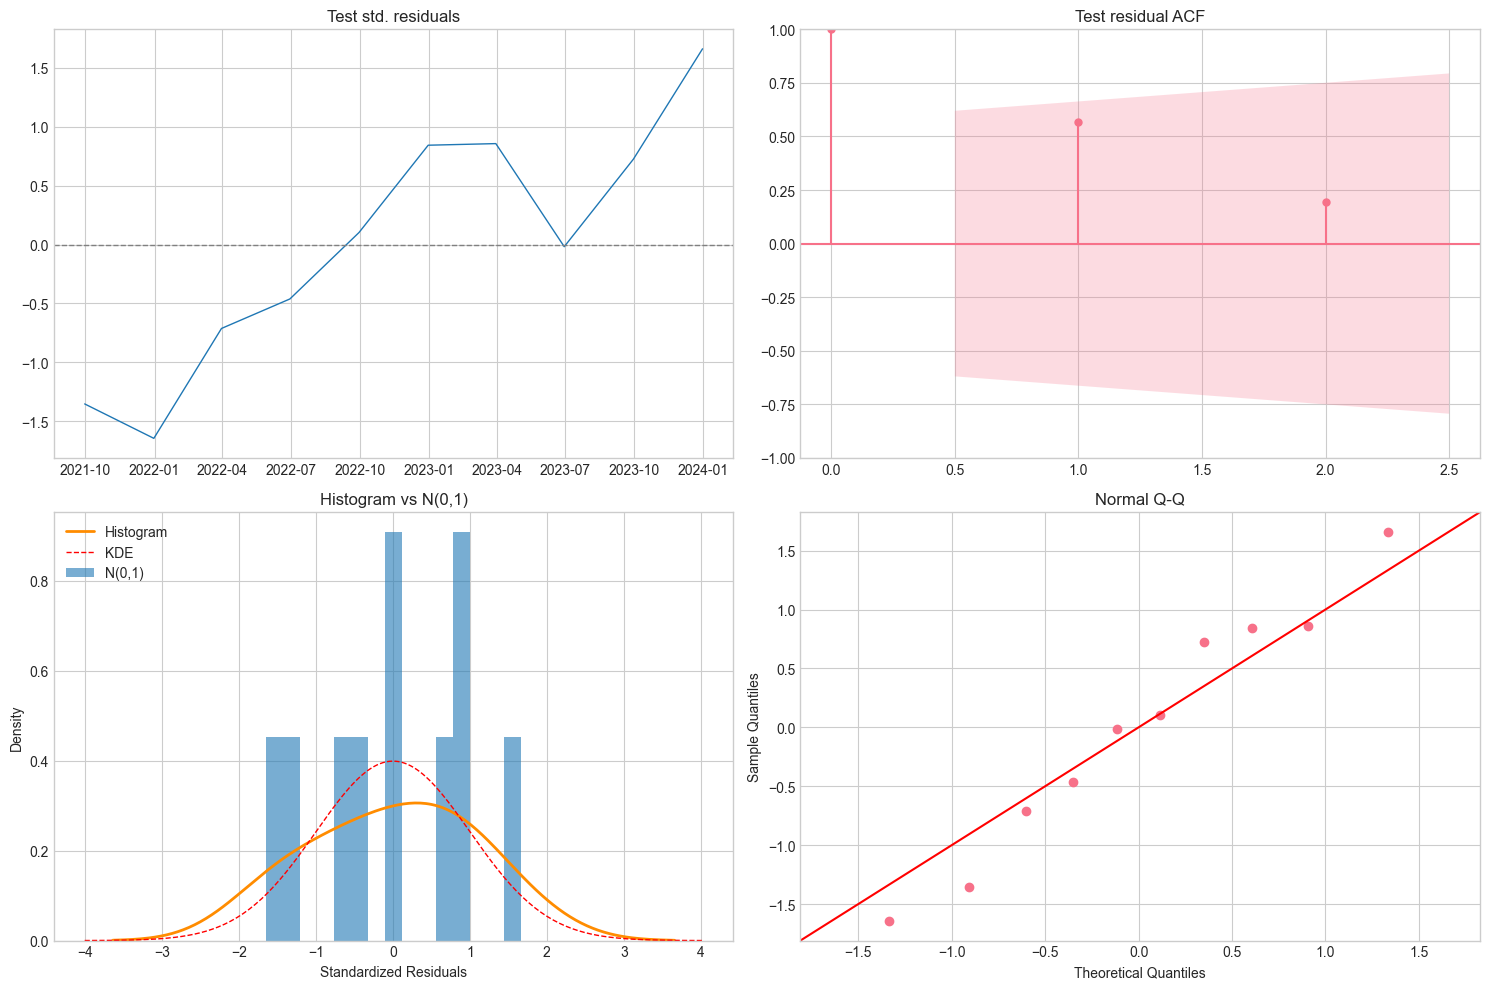

In [46]:
# Residual diagnostics

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(std_resid, lw=1, color='tab:blue')
axes[0, 0].axhline(0, color='gray', ls='--', lw=1)
axes[0, 0].set_title('Test std. residuals')

# ACF of standardized residuals
plot_acf(std_resid, lags=min(12, max(1, len(std_resid)//5)), ax=axes[0, 1])
axes[0, 1].set_title('Test residual ACF')

# Histogram of standardized residuals
axes[1, 0].hist(std_resid, bins=15, density=True, alpha=0.6, color='tab:blue')
sns.kdeplot(std_resid, ax=axes[1, 0], color='darkorange', lw=2) # plot kernel density estimate
xs = np.linspace(*axes[1, 0].get_xlim(), 200) # plot normal distribution for comparison
axes[1, 0].plot(xs, stats.norm.pdf(xs, 0, 1), 'r--', lw=1)
axes[1, 0].set_title('Histogram vs N(0,1)')
axes[1, 0].set_xlabel('Standardized Residuals')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend(['Histogram', 'KDE', 'N(0,1)'], loc='upper left')

# Q-Q plot of standardized residuals
sm.ProbPlot(std_resid).qqplot(line='45', ax=axes[1, 1])
axes[1, 1].set_title('Normal Q-Q')

plt.tight_layout()
plt.savefig('graphs/time_dep/time_deposits_residual_diagnostics.png')
plt.show()


In [47]:
# Statistics on test residuals

# Check residual sample size and adjust lags accordingly
n_resid = len(std_resid)
max_safe_lag = max(1, n_resid // 2 - 1)  # Ensure at least 1 lag but don't exceed sample limits
test_lags = [lag for lag in [4, 8, 12] if lag <= max_safe_lag]

if test_lags:  # Only run if we have valid lags
    lb = acorr_ljungbox(std_resid, lags=test_lags, return_df=True)
    print('Ljung–Box p-values:', {int(k): float(v) for k, v in lb['lb_pvalue'].to_dict().items()})
else:
    print(f'Sample too small (n={n_resid}) for meaningful Ljung-Box test')

jb_stat, jb_p, skew, kurt = jarque_bera(std_resid)
print(f'Jarque–Bera: stat={jb_stat:.3f}, p={jb_p:.3f}, skew={skew:.3f}, kurt={kurt:.3f}')



Ljung–Box p-values: {4: 0.25783781429269065}
Jarque–Bera: stat=0.447, p=0.800, skew=-0.119, kurt=1.992


In [48]:
#Load scenarios data
scenarios = pd.read_csv('extracted_data/scenarios.csv', index_col=['Scenario Name', 'Date'], parse_dates=['Date'], date_format='%Y-%m-%d')

In [49]:
scenarios.head()

Real GDP  Real GDP growth   Nominal GDP  \
Scenario Name        Date                                                      
Supervisory Baseline 2024-03-31  22735.953138              1.0  28180.653984   
                     2024-06-30  22775.741055              0.7  28384.963725   
                     2024-09-30  22826.986473              0.9  28604.947194   
                     2024-12-31  22912.587672              1.5  28862.391719   
                     2025-03-31  23015.694317              1.8  29158.231234   

                                 Nominal GDP growth  Real disposable income  \
Scenario Name        Date                                                     
Supervisory Baseline 2024-03-31                 3.2            16961.584792   
                     2024-06-30                 2.9            17037.911923   
                     2024-09-30                 3.1            17114.582527   
                     2024-12-31                 3.6            17200.155440   
                     2025-03-31                 4.1            17303.356372   

                                 Real disposable income growth  \
Scenario Name        Date                                        
Supervisory Baseline 2024-03-31                            2.5   
                     2024-06-30                            1.8   
                     2024-09-30                            1.8   
                     2024-12-31                            2.0   
                     2025-03-31                            2.4   

                                 Nominal disposable income  \
Scenario Name        Date                                    
Supervisory Baseline 2024-03-31               20690.266217   
                     2024-06-30               20897.168879   
                     2024-09-30               21106.140568   
                     2024-12-31               21322.478508   
                     2025-03-31               21562.356392   

                                 Nominal disposable income growth  \
Scenario Name        Date                                           
Supervisory Baseline 2024-03-31                               4.6   
                     2024-06-30                               4.0   
                     2024-09-30                               4.0   
                     2024-12-31                               4.1   
                     2025-03-31                               4.5   

                                 Unemployment rate  \
Scenario Name        Date                            
Supervisory Baseline 2024-03-31                3.9   
                     2024-06-30                4.1   
                     2024-09-30                4.2   
                     2024-12-31                4.3   
                     2025-03-31                4.3   

                                 Consumer Price Index (Level)  ...  \
Scenario Name        Date                                      ...   
Supervisory Baseline 2024-03-31                    309.931186  ...   
                     2024-06-30                    311.698122  ...   
                     2024-09-30                    313.551711  ...   
                     2024-12-31                    315.339289  ...   
                     2025-03-31                    317.059527  ...   

                                 3-month Treasury rate  5-year Treasury yield  \
Scenario Name        Date                                                       
Supervisory Baseline 2024-03-31                    5.3                    4.2   
                     2024-06-30                    5.0                    4.0   
                     2024-09-30                    4.6                    3.9   
                     2024-12-31                    4.2                    3.8   
                     2025-03-31                    3.9                    3.6   

                                 10-year Treasury yield  BBB corporate yield  \
Scenario Name        D

In [50]:
# Use the complete historical base data X for proper lag calculation
# X contains the raw economic variables without lags
# exog_aligned contains the differenced and lagged variables used in the model

# Forecast horizon
forecast_dates = pd.date_range(start='2024-03-31', periods=13, freq='QE')
scenario_names = scenarios.index.get_level_values('Scenario Name').unique()
forecasts = {}

for scenario_name in scenario_names:
    scenario_data = scenarios.loc[scenario_name].copy()
    
    # Create complete time series combining historical X and scenario data
    # This ensures we have enough history to compute all required lags
    full_series = {}
    
    # Real GDP: need diff and lag 2
    full_series['Real GDP'] = pd.concat([
        X['Real GDP'],
        scenario_data['Real GDP']
    ]).drop_duplicates()
    
    # Real GDP growth: need lag 2
    full_series['Real GDP growth'] = pd.concat([
        X['Real GDP growth'],
        scenario_data['Real GDP growth']
    ]).drop_duplicates()
    
    # Unemployment rate: need lag 1
    full_series['Unemployment rate'] = pd.concat([
        X['Unemployment rate'],
        scenario_data['Unemployment rate']
    ]).drop_duplicates()
    
    # CPI inflation rate: need lag 2
    full_series['CPI inflation rate'] = pd.concat([
        X['CPI inflation rate'],
        scenario_data['CPI inflation rate']
    ]).drop_duplicates()
    
    # 3-month Treasury rate: need lag 2
    full_series['3-month Treasury rate'] = pd.concat([
        X['3-month Treasury rate'],
        scenario_data['3-month Treasury rate']
    ]).drop_duplicates()
    
    # 5-year Treasury yield: need lag 2
    full_series['5-year Treasury yield'] = pd.concat([
        X['5-year Treasury yield'],
        scenario_data['5-year Treasury yield']
    ]).drop_duplicates()
    
    # 10-year Treasury yield: need lag 2
    full_series['10-year Treasury yield'] = pd.concat([
        X['10-year Treasury yield'],
        scenario_data['10-year Treasury yield']
    ]).drop_duplicates()
    
    # BBB corporate yield: need lag 2
    full_series['BBB corporate yield'] = pd.concat([
        X['BBB corporate yield'],
        scenario_data['BBB corporate yield']
    ]).drop_duplicates()
    
    # Mortgage rate: need lag 2
    full_series['Mortgage rate'] = pd.concat([
        X['Mortgage rate'],
        scenario_data['Mortgage rate']
    ]).drop_duplicates()
    
    # Prime rate: need lag 2
    full_series['Prime rate'] = pd.concat([
        X['Prime rate'],
        scenario_data['Prime rate']
    ]).drop_duplicates()
    
    # Market Volatility Index (Level): need lag 1
    full_series['Market Volatility Index (Level)'] = pd.concat([
        X['Market Volatility Index (Level)'],
        scenario_data['Market Volatility Index (Level)']
    ]).drop_duplicates()
    
    # Consumer Price Index (Level): need diff and lag 1 for forecast
    full_series['Consumer Price Index (Level)'] = pd.concat([
        X['Consumer Price Index (Level)'],
        scenario_data['Consumer Price Index (Level)']
    ]).drop_duplicates()
    
    # House Price Index (Level): need diff and lag 3
    full_series['House Price Index (Level)'] = pd.concat([
        X['House Price Index (Level)'],
        scenario_data['House Price Index (Level)']
    ]).drop_duplicates()
    
    # Now create the lagged exog matrix for forecast dates only
    scenario_X = pd.DataFrame(index=forecast_dates)
    
    # Apply lags to the full series and extract forecast period
    scenario_X['Real GDP_lag2'] = full_series['Real GDP'].diff().shift(2).reindex(forecast_dates)
    scenario_X['Real GDP growth_lag2'] = full_series['Real GDP growth'].shift(2).reindex(forecast_dates)
    scenario_X['Unemployment rate_lag1'] = full_series['Unemployment rate'].shift(1).reindex(forecast_dates)
    scenario_X['CPI Price Index (Level)_diff_lag1'] = full_series['Consumer Price Index (Level)'].diff().shift(1).reindex(forecast_dates)
    scenario_X['CPI inflation rate_lag2'] = full_series['CPI inflation rate'].shift(2).reindex(forecast_dates)
    scenario_X['3-month Treasury rate_lag2'] = full_series['3-month Treasury rate'].shift(2).reindex(forecast_dates)
    scenario_X['5-year Treasury yield_lag2'] = full_series['5-year Treasury yield'].shift(2).reindex(forecast_dates)
    scenario_X['10-year Treasury yield_lag2'] = full_series['10-year Treasury yield'].shift(2).reindex(forecast_dates)
    scenario_X['BBB corporate yield_lag2'] = full_series['BBB corporate yield'].shift(2).reindex(forecast_dates)
    scenario_X['Mortgage rate_lag2'] = full_series['Mortgage rate'].shift(2).reindex(forecast_dates)
    scenario_X['Prime rate_lag2'] = full_series['Prime rate'].shift(2).reindex(forecast_dates)
    scenario_X['House Price Index (Level)_diff_lag3'] = full_series['House Price Index (Level)'].diff().shift(3).reindex(forecast_dates)
    scenario_X['Market Volatility Index (Level)_lag1'] = full_series['Market Volatility Index (Level)'].shift(1).reindex(forecast_dates)
    
    # Dummies (set to 0 for future periods)
    scenario_X['GFC_Dummy'] = 0
    scenario_X['COVID_Dummy'] = 0
    
    # Reorder columns to match model specification
    scenario_X = scenario_X[exog_aligned.columns]
    
    # Handle any remaining NaN values
    scenario_X = scenario_X.ffill().fillna(0)
    
    # Generate forecast using the fitted model
    forecast = res.get_forecast(steps=len(forecast_dates), exog=scenario_X)
    y_forecast = forecast.predicted_mean.clip(lower=0)
    y_forecast.index = forecast_dates
    ci = forecast.conf_int(alpha=0.05) 
    ci.index = forecast_dates
    
    forecasts[scenario_name] = {'mean': y_forecast, 'ci': ci}

In [51]:
forecasts

{'Supervisory Baseline': {'mean': 2024-03-31    1.439518e+06
  2024-06-30    1.521308e+06
  2024-09-30    1.643921e+06
  2024-12-31    1.973364e+06
  2025-03-31    1.042618e+06
  2025-06-30    1.748331e+06
  2025-09-30    1.736242e+06
  2025-12-31    1.794161e+06
  2026-03-31    1.790494e+06
  2026-06-30    1.792998e+06
  2026-09-30    1.790408e+06
  2026-12-31    1.793136e+06
  2027-03-31    1.792698e+06
  Freq: QE-DEC, Name: predicted_mean, dtype: float64,
  'ci':             lower Time_Deposits  upper Time_Deposits
  2024-03-31         1.376041e+06         1.502995e+06
  2024-06-30         1.428413e+06         1.614204e+06
  2024-09-30         1.528724e+06         1.759118e+06
  2024-12-31         1.839521e+06         2.107207e+06
  2025-03-31         8.923287e+05         1.192906e+06
  2025-06-30         1.583220e+06         1.913442e+06
  2025-09-30         1.557534e+06         1.914951e+06
  2025-12-31         1.602820e+06         1.985503e+06
  2026-03-31         1.587302e+06   

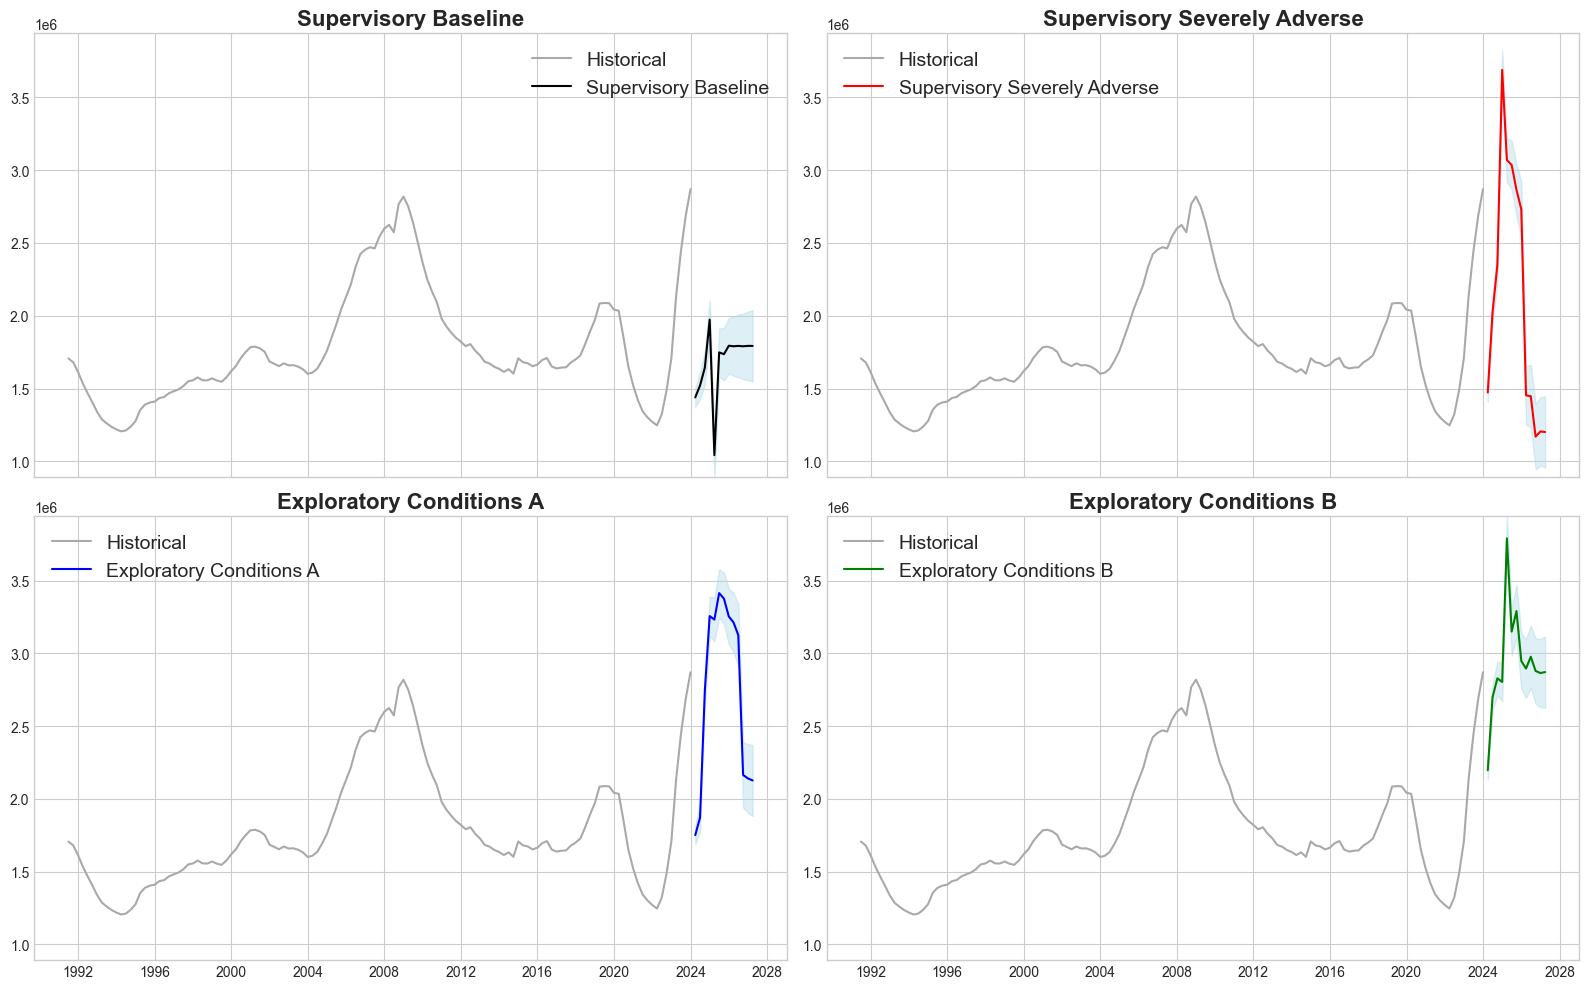

In [62]:
# Define colors dictionary
colors = {
    'Supervisory Baseline': 'black',
    'Supervisory Severely Adverse': 'red',
    'Exploratory Conditions A': 'blue',
    'Exploratory Conditions B': 'green'
}

scenario_list = list(forecasts.keys())
titles = {
    'Supervisory Baseline': 'Supervisory Baseline',
    'Supervisory Severely Adverse': 'Supervisory Severely Adverse',
    'Exploratory Conditions A': 'Exploratory Conditions A',
    'Exploratory Conditions B': 'Exploratory Conditions B'
}

# --- Determine global y-axis limits for all scenarios ---
y_min = min(
    y.min(), 
    min(forecasts[s]['ci'].iloc[:, 0].min() for s in scenario_list)
)
y_max = max(
    y.max(), 
    max(forecasts[s]['ci'].iloc[:, 1].max() for s in scenario_list)
)

# --- Create 2x2 grid ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(scenario_list):
        scenario_name = scenario_list[i]
        forecast_data = forecasts[scenario_name]
        color = colors.get(scenario_name, 'yellow')

        # Plot historical + forecast
        ax.plot(y.index, y, label='Historical', color='darkgray')
        ax.plot(forecast_data['mean'].index, forecast_data['mean'], 
                label=f'{scenario_name}', color=color)
        ax.fill_between(forecast_data['ci'].index, 
                        forecast_data['ci'].iloc[:, 0], 
                        forecast_data['ci'].iloc[:, 1], 
                        color='lightblue', alpha=0.4)
        
        # Titles and labels
        ax.set_title(titles.get(scenario_name, scenario_name), fontweight='bold', fontsize=16)
        ax.set_ylim(y_min, y_max)                # keep same scale
        ax.tick_params(left=True, labelleft=True) # ensure y-axis on left
        ax.legend(prop={'size': 14}, framealpha=0.9)
        ax.grid(True)

        # --- Save each subplot separately ---
        fig_single, ax_single = plt.subplots(figsize=(8, 5))
        ax_single.plot(y.index, y, label='Historical', color='darkgray')
        ax_single.plot(forecast_data['mean'].index, forecast_data['mean'], label=f'{scenario_name}', color=color)
        ax_single.fill_between(forecast_data['ci'].index, 
                               forecast_data['ci'].iloc[:, 0], 
                               forecast_data['ci'].iloc[:, 1], 
                               color='lightblue', alpha=0.4)
        ax_single.set_title(titles.get(scenario_name, scenario_name), fontweight='bold', fontsize=16)
        ax_single.set_ylim(y_min, y_max)          # same scale
        ax.tick_params(left=True, labelleft=True) # ensure y-axis on left
        ax_single.legend(prop={'size': 14}, framealpha=0.9)
        ax_single.grid(True)
        plt.tight_layout()
        plt.savefig(f'graphs/time_dep/time_deposits_{scenario_name}_forecast.png', dpi=300, bbox_inches='tight')
        plt.close(fig_single)
    else:
        ax.axis('off')  # hide any empty subplots

# --- Save combined 2x2 grid ---
plt.tight_layout()
plt.savefig('graphs/time_dep/time_deposits_forecasts.png', dpi=300, bbox_inches='tight')
plt.show()


**Supervisory Baseline (black line)**

- 3-month Treasury falls from 5.3% to 3.1%, 5- and 10-year yields ease modestly, CPI inflation declines from 2.4% to 1.3%, and unemployment holds around 4%

- Time deposits first dip slightly (banks lower rates in line with the Fed), then resume a gentle rise from $1.5Tn to about $1.8Tn as income growth (real disposable income up 2.5%→1.8%) and steady GDP expansion underpin demand for locked-in longer rates

**Supervisory Severely Adverse (red line)**

- Short-term rates crash toward zero, long rates fall sharply, unemployment spikes to 10%, and market volatility soars

- Deposits jump from $1.5Tn to $3.7Tn as households and firms flee risk and lock in whatever yields remain, then gradually taper back to $1.2Tn by 2027 as rates normalize but risk aversion persists

**Exploratory Conditions A (blue line)**
- A sharp recession (GDP growth –11.6%), peak short-term rates at 6.8%, then swift recovery: unemployment rises to 8% then falls, inflation peaks then subsides

- Time deposits surge to $3.3Tn during the downturn (high rates plus safety demand), then recede to $2.2Tn as rates drop and the economy rebounds, before stabilizing near $2.0Tn — matching the boom-and-bust pattern in rates and risk

**Exploratory Conditions B (green line)**

- A prolonged slowdown with only gradual rate cuts (3mo TSY from 5.3% to 3.1%), unemployment around 6%, and muted income growth

- Deposits climb steadily from $1.5Tn toward $2.9Tn by 2027 as elevated but falling yields and persistent risk aversion foster a slow, sustained shift into time-locked balances